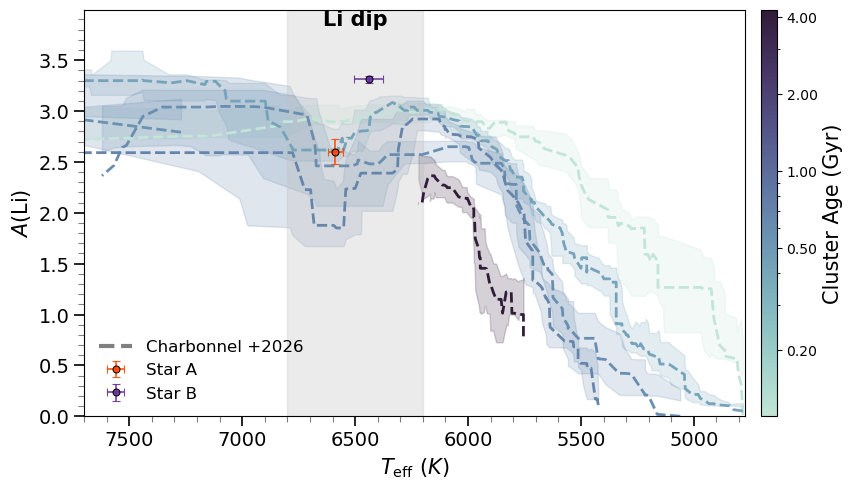

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.ticker import MultipleLocator
from scipy.signal import medfilt
import seaborn as sns

fig, ax_main = plt.subplots(figsize=(9, 5))

clusters = {
    "Pleiades": {"file": "pleiadesdata.csv", "age": "0.11 Gyr"},
    "M48":      {"file": "m48data.csv",      "age": "0.42 Gyr"},
    "ComaBer":  {"file": "comaberdata.csv",  "age": "0.56 Gyr"},
    "Praesepe": {"file": "praesepedata.csv", "age": "0.59 Gyr"},
    "Hyades":   {"file": "hyadesdata.csv",   "age": "0.68 Gyr"},
    "M67":      {"file": "m67data.csv",      "age": "4.26 Gyr"}}

ages_num = [float(info["age"].split()[0]) for info in clusters.values()]

cmap = sns.cubehelix_palette(start=0.5, rot=-0.5, as_cmap=True)
norm = mcolors.LogNorm(vmin=min(ages_num), vmax=max(ages_num))

for name, info in clusters.items():
    try:
        df = pd.read_csv(info["file"])
        df.columns = ["x", "y"] + list(df.columns[2:])
        df = df.dropna(subset=["x", "y"]).sort_values("x")

        n_points = len(df)
        if n_points == 0:
            continue

        target_kernel = 15
        k_size = min(target_kernel, n_points)
        if k_size % 2 == 0:
            k_size -= 1
        k_size = max(1, k_size)

        median_ali = medfilt(df["y"].values, kernel_size=k_size)
        rolling = df["y"].rolling(window=k_size, center=True, min_periods=1)
        p25 = rolling.quantile(0.25)
        p75 = rolling.quantile(0.75)

        age_val = float(info["age"].split()[0])
        cluster_color = cmap(norm(age_val))

        ax_main.fill_between(df["x"], p25, p75, color=cluster_color, alpha=0.2)
        ax_main.plot(df["x"], median_ali, color=cluster_color, lw=2, linestyle='--')

    except FileNotFoundError:
        print(f"File {info['file']} not found. Skipping {name}.")


ax_main.plot([], [], color='grey', linestyle='--', lw=3, label="Charbonnel +2026")

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([]) 
cbar = plt.colorbar(sm, ax=ax_main, pad=0.02, aspect=25, ticks=[0.1, 0.2, 0.5, 1.0, 2.0, 4.0])
cbar.set_label("Cluster Age (Gyr)", fontsize=15)
cbar.ax.yaxis.set_major_formatter(plt.FormatStrFormatter("%.2f"))

wb_pairs = [{"name": "Star A", "teff": [6587], "teff_err": [34], "ali": [2.60], "ali_err": [0.123]},
    {"name": "Star B", "teff": [6439], "teff_err": [64], "ali": [3.31], "ali_err": [0.031]}]

pair_colors = ["orangered", "rebeccapurple", "forestgreen", "mediumpurple", "navy", "mediumseagreen", "cadetblue", "sienna", "tomato", "orchid"]

for i, pair in enumerate(wb_pairs):
    color = pair_colors[i % len(pair_colors)]
    ax_main.errorbar(
        pair["teff"],
        pair["ali"],
        xerr=pair.get("teff_err", None),
        yerr=pair.get("ali_err", None),
        fmt=".",
        ms=10,
        mfc=color,
        mec="black",
        mew=0.8,
        ecolor=color,
        capsize=3,
        elinewidth=1.2,
        alpha=0.9,
        zorder=5,
        label=pair["name"])

li_dip_min, li_dip_max = 6350, 6800
li_dip_sunmin, li_dip_sunmax = 6200, 6650
ax_main.axvspan(li_dip_sunmin, li_dip_max, color="silver", alpha=0.3, zorder=1, label=None)
ax_main.text((li_dip_sunmin + li_dip_max) / 2, 3.9, "Li dip", color="black", fontsize=15, ha="center", va="center", zorder=3, fontweight="bold")

ax_main.set_xlim(7700, 4775)
ax_main.set_ylim(0.0, 3.99)
ax_main.xaxis.set_minor_locator(MultipleLocator(100))
ax_main.yaxis.set_minor_locator(MultipleLocator(0.1))

ax_main.tick_params(axis="both", which="major", length=7, width=1.2, colors="black", labelsize=14)
ax_main.tick_params(axis="both", which="minor", length=4, width=0.8, color="gray")

ax_main.set_xlabel(r'${T_{\mathrm{eff}}}\ {(K)}$', fontsize=15)
ax_main.set_ylabel(r'${A(\mathrm{Li})}$', fontsize=15)

ax_main.grid(False)
ax_main.legend(loc="lower left", frameon=False, facecolor="none", edgecolor="none", fontsize="large")

plt.tight_layout()
plt.savefig("A(Li)_plot.png", dpi=300)
plt.show()